In [89]:
import math
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


from gm.data.mnist import train_loader

from gm.models.flow_matching_model import train_fmm, sample_fmm, interpolate_linear, get_target_velocity

In [90]:
SEED = 42
DEVICE = 'mps'

steps = 1_000
batch_size = 128
lr = 1e-3

In [91]:
def sample_noise(batch_size):
    return torch.randn(batch_size, 1, 28, 28)

sample_data = lambda batch_size: next(iter(train_loader))

In [92]:
x, y = sample_data(1)

In [93]:
def plot_losses(losses):
    fig, ax = plt.subplots()

    ax.plot(losses, label="Loss", color="tab:blue", alpha=0.5)
    ws = 10
    smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
    ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color="tab:blue")

    plt.legend()
    plt.grid()
    plt.show()

def plot_samples(x, n_cols=8, figsize_scale=1.2):
    # x = x.detach().cpu().view(-1, 28, 28)  # (N, 784) -> (N, 28, 28)
    x = x.detach().cpu().squeeze(1)  
    n = x.shape[0]
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_scale, n_rows * figsize_scale))
    axes = axes.flatten() if n > 1 else [axes]

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(x[i], cmap="gray")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [94]:
class SinusodialTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        t = t.view(-1)
        half_dim = self.dim // 2
        freqs = torch.exp(-math.log(10_000) * torch.arange(half_dim, device=t.device) / (half_dim - 1))
        args = t[:, None] * freqs[None, :]

        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class FiLMConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()

        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.cond_proj = nn.Linear(emb_dim, out_ch * 2)
        self.act = nn.SiLU()
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, cond):
        h = self.act(self.norm1(self.conv1(x)))
        scale, shift = self.cond_proj(cond).chunk(2, dim=-1)
        h = h * (1 + scale[:, :, None, None]) + shift[:, :, None, None]
        h = self.act(self.norm2(self.conv2(h)))

        return h + self.skip(x)


class UNet(nn.Module):
    def __init__(self, in_ch = 1, base_ch = 32, time_emb_dim = 128):
        super().__init__()

        self.in_ch = in_ch

        self.time_embed = nn.Sequential(
            SinusodialTimeEmbedding(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        self.label_embed = nn.Embedding(num_embeddings=10, embedding_dim=time_emb_dim, device=DEVICE)

        self.down1 = FiLMConvBlock(in_ch, base_ch, time_emb_dim)
        self.pool1 = nn.Conv2d(base_ch, base_ch, 4, stride=2, padding=1)

        self.down2 = FiLMConvBlock(base_ch, base_ch * 2, time_emb_dim)
        self.pool2 = nn.Conv2d(base_ch * 2, base_ch * 2, 4, stride=2, padding=1)

        self.bottleneck = FiLMConvBlock(base_ch * 2, base_ch * 4, time_emb_dim)

        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, stride=2, padding=1)
        self.up_block2 = FiLMConvBlock(base_ch * 4, base_ch * 2, time_emb_dim)

        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, stride=2, padding=1)
        self.up_block1 = FiLMConvBlock(base_ch * 2, base_ch, time_emb_dim)

        self.out_conv = nn.Conv2d(base_ch, in_ch, 1)

    def forward(self, t, x, y):
        t_emb = self.time_embed(t)
        y_emb = self.label_embed(y)

        cond = t_emb + y_emb

        h1 = self.down1(x, cond)
        h2 = self.down2(self.pool1(h1), cond)
        h = self.bottleneck(self.pool2(h2), cond)

        h = self.up2(h)
        h = self.up_block2(torch.cat([h, h2], dim=1), cond)
        h = self.up1(h)
        h = self.up_block1(torch.cat([h, h1], dim=1), cond)

        return self.out_conv(h)


In [95]:

def loss(fmm, x_0, x_1, t, y):
    x_t = interpolate_linear(x_0, x_1, t)
    v_target = get_target_velocity(x_0, x_1)
    v_pred = fmm(t, x_t, y)

    loss = ((v_pred - v_target)**2).mean()

    return loss


def train_conditional_fmm(model, optimizer, sample_noise, sample_data, steps, batch_size, device):
    losses = []
    with tqdm(range(steps)) as pb:
        for i in pb:
            x_0 = sample_noise(batch_size).to(device)
            x_1, y = sample_data(batch_size)
            x_1 = x_1.to(device)
            y = y.to(device)
            # t = torch.rand(x_1.shape[0], device=device).unsqueeze(-1)
            t = torch.rand(x_1.shape[0], device=device).view(-1, 1, 1, 1)
            
            optimizer.zero_grad()
            l = loss(model, x_0, x_1, t, y)
            l.backward()
            optimizer.step()

            pb.set_postfix({'Loss': f'{l.item():.2f}'})
            losses.append(l.item())

    return losses

@torch.no_grad()
def sample_conditional_fmm(fmm, x_0, y, n_steps = 100, device='cpu'):
    x = x_0
    dt = 1.0 / n_steps

    for i in range(n_steps):
        t_val = i * dt
        t = torch.full((x.shape[0], 1), t_val, device=device)
        v = fmm(t, x, y)
        x = x + v * dt

    return x

100%|██████████| 1000/1000 [01:44<00:00,  9.53it/s, Loss=0.17]


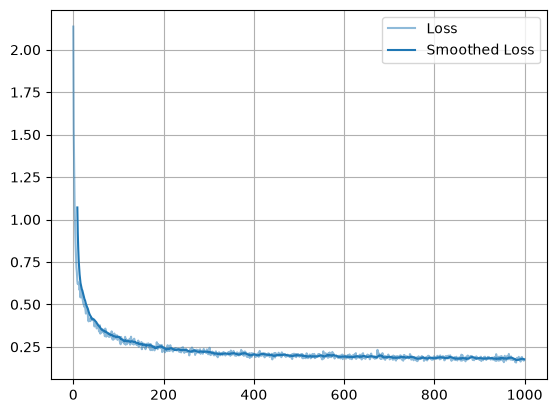

In [96]:
fmm = UNet(in_ch=1, base_ch=32, time_emb_dim=128).to(DEVICE)


opt = torch.optim.Adam(fmm.parameters(), lr)
losses = train_conditional_fmm(fmm, opt, sample_noise, sample_data, steps, batch_size, DEVICE)
plot_losses(losses)

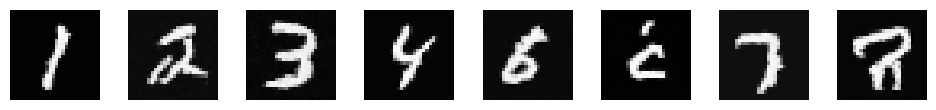

In [97]:
fmm.eval()
x_0 = sample_noise(8).to(DEVICE)
y = torch.tensor(np.array([1, 2, 3, 4, 5, 6, 7, 8])).to(DEVICE)
samples = sample_conditional_fmm(fmm, x_0, y, n_steps=100, device=DEVICE).cpu()
plot_samples(samples)